# 68 — Improving the singleton filter: objectives, features and training trajectories

The original loss/health objective and a linear-probe CE objective are crossed with current and richer features. Every live SSL update uses one image. Each main gate has its own random control with identical per-clip update counts. Linear-probe accuracy on fresh query images is the primary final evaluation. The rich policy uses labels on a separate development bank for task-gradient alignment; incoming images require no labels. All models and thresholds are frozen before fresh test trajectories. No final test label or metric feeds into decisions.


**Main finding: this test does not establish an improved linear-probe filter.** Accept-all has the highest mean final accuracy (59.42%, up 1.57 percentage points from the common fork). The best mean among the learned gates is loss/health with richer features (58.85%). Its accuracy difference from its matched random control is 0.256944 [-0.173611, 0.6875] pp. That interval includes zero. Both probe-CE gates have lower accuracy than accept-all, with exploratory paired intervals excluding zero. None of the four gates establishes a positive accuracy increment over its own random-count control. These are six-history, unadjusted exploratory intervals.


In [1]:
from pathlib import Path
import json
import numpy as np
ROOT = Path('C:\\CAFL-E\\project\\cafl4ds\\outputs\\single-image-filter-factorial\\20261021-probe-feature')
def read(name): return json.loads((ROOT/name).read_text(encoding='utf-8'))
s=read('summary.json'); a=dict(np.load(ROOT/'endpoints.npz',allow_pickle=False)); metrics=a['metrics'].tolist(); arms=a['arms'].tolist()
def f(v): return format(float(v),'.6g')
def ci(r): return f(r['mean'])+' ['+f(r['ci95'][0])+', '+f(r['ci95'][1])+']'
def table(headers, rows):
    rows=[list(r) for r in rows]
    if '_table_sink' in globals(): _table_sink(headers,rows)
    else:
        import html
        from IPython.display import HTML,display
        value='<table><tr>'+''.join('<th>'+html.escape(h)+'</th>' for h in headers)+'</tr>'
        for row in rows: value+='<tr>'+''.join('<td>'+html.escape(str(v))+'</td>' for v in row)+'</tr>'
        display(HTML(value+'</table>'))
for name in ['calibration-verification.json','collection-verification.json','numerical-verification.json','physical-verification.json','summary-verification.json']: assert read(name)['passed']
np.testing.assert_allclose(a['after'][:,:, [metrics.index(m) for m in a['reader_metrics']]],a['panels_after'].mean(2))
print('Verified audits and all panel means. Six histories, two training seeds, three support panels; twelve arms.')


Verified audits and all panel means. Six histories, two training seeds, three support panels; twelve arms.


## What changed

J retains reconstruction/warm plus two .25-weight warm-relative rank/variance shortfall penalties. The probe target is mean refitted linear-probe CE change on 200 DEVELOPMENT images. Four old development histories fit candidate models; two whole histories choose ridge versus histogram boosting. Targets average three training views and three support panels. Final models refit all six development histories and remain frozen. The threshold is min(0, validation prediction60th percentile). A negative prediction is required, so this is not a forced60% admission policy.

Current features have42 coordinates. Rich features have86: current inputs plus bank-cluster distances and reconstruction summaries, recent-image similarities, older health changes, and candidate gradient/proposed AdamW displacement aligned with a fixed-current-head task gradient. Head-fixed gradient alignment is an approximation; the target refits the probe. Existing support panels are reused. The200 development and400 evaluation query images are new and disjoint; the60 test clips were not used in prior singleton histories.


In [2]:
selection=read('model-selection.json')
table(['Gate','Selected family','Frozen threshold','Validation RMSE','Validation MAE','Zero RMSE','Zero MAE'], [[k,r['family'],f(r['threshold']),f(r['validation_rmse']),f(r['validation_mae']),f(r['zero_rmse']),f(r['zero_mae'])] for k,r in selection.items()])


Gate,Selected family,Frozen threshold,Validation RMSE,Validation MAE,Zero RMSE,Zero MAE
J_state,linear,-0.00156551,0.00454942,0.00330821,0.00622399,0.00366864
J_base,nonlinear,-0.000383619,0.00450019,0.00275246,0.00622399,0.00366864
J_rich,linear,-0.00144519,0.0034485,0.00272691,0.00622399,0.00366864
probe_state,linear,0,0.0104238,0.00232491,0.0112986,0.00172391
probe_base,linear,-6.8108e-05,0.0103533,0.00243026,0.0112986,0.00172391
probe_rich,linear,0,0.0103629,0.00230856,0.0112986,0.00172391


## How training changes linear-probe performance

Every dot is a measured refitted-probe checkpoint, averaged across three support panels, two seeds and six histories. Bands resample entire histories and are exploratory95% intervals. Matched random has a separate schedule for each gate. The arrival-axis comparison fixes stream exposure; the update-axis view shows mean cumulative accepted singleton updates. Those are two views of the same experiment, not independent tests.


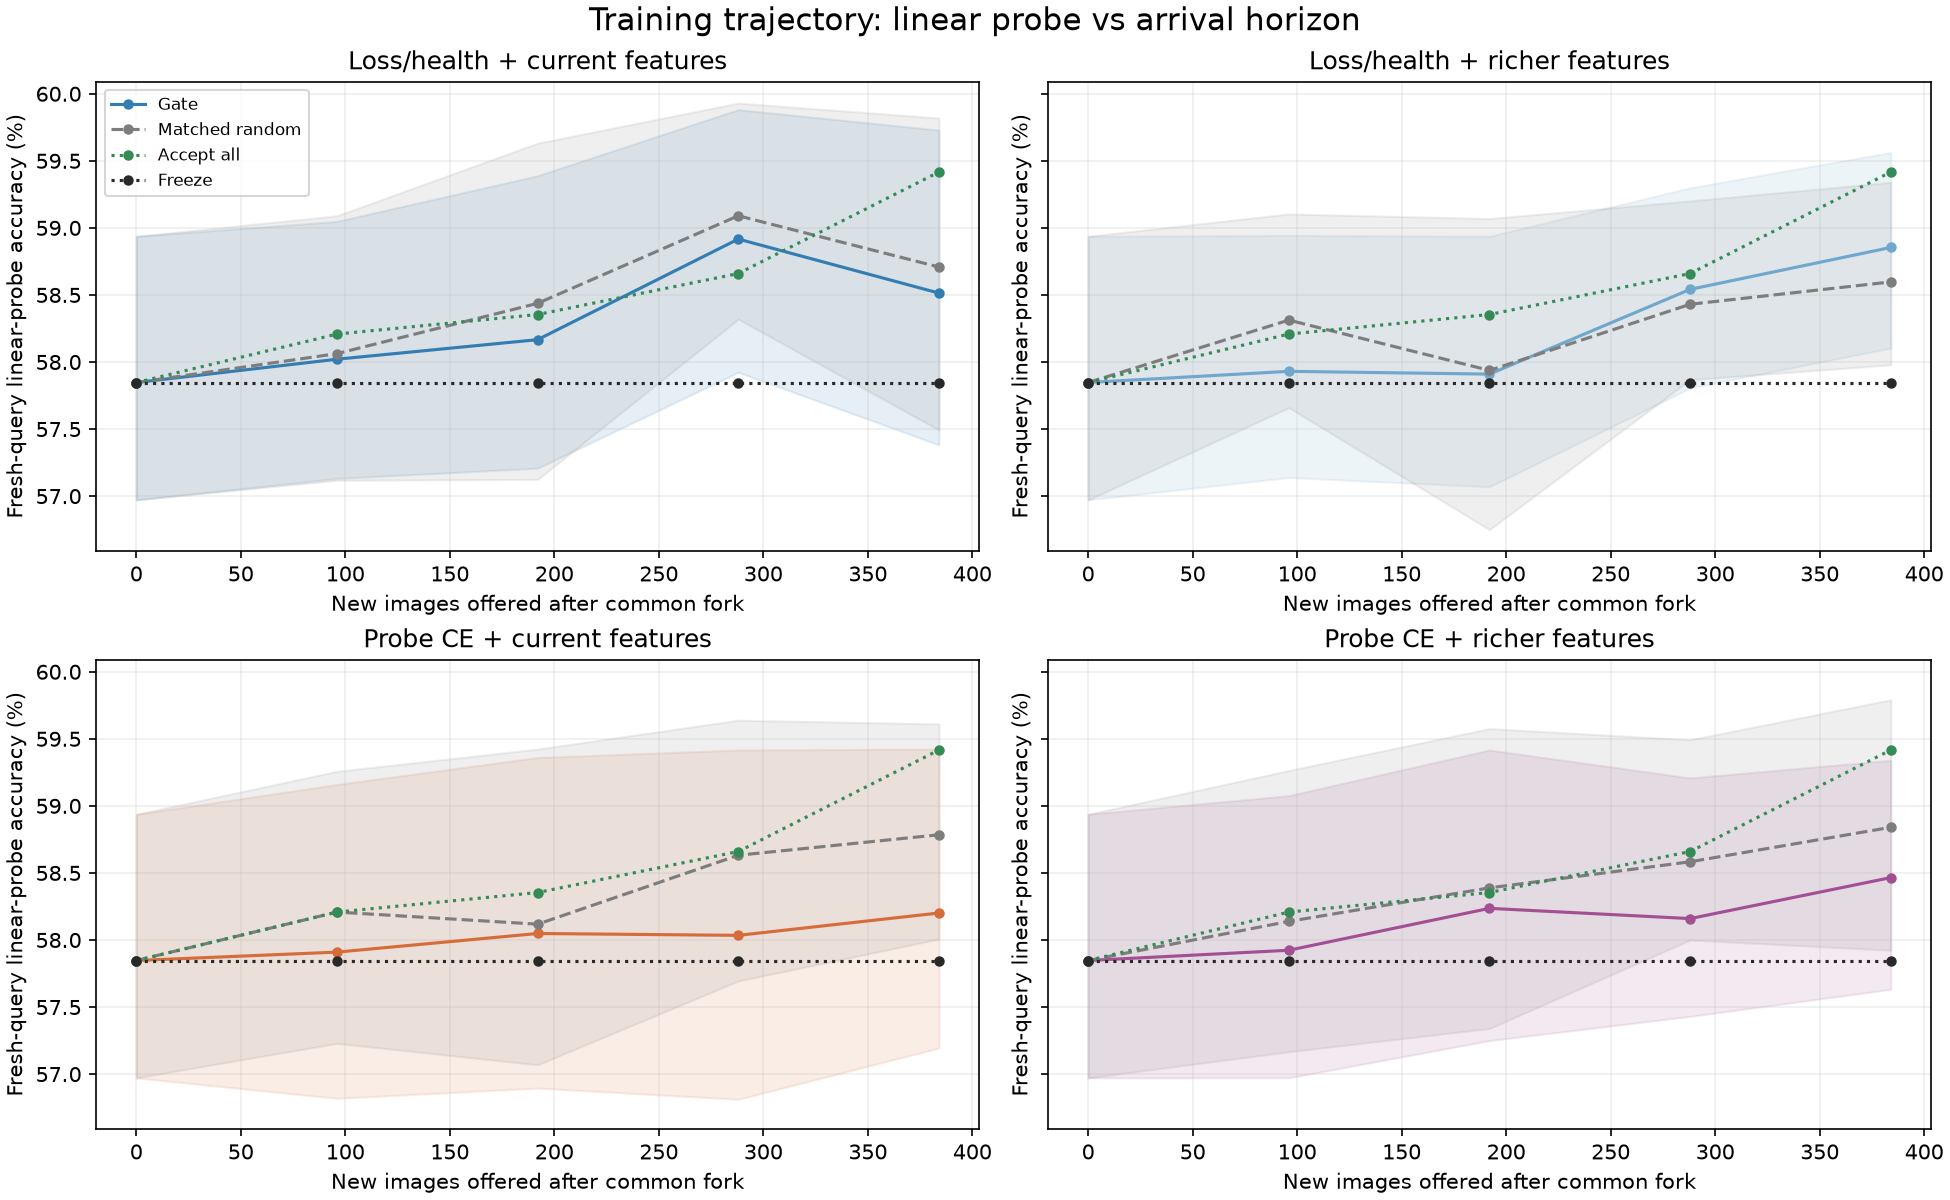

Primary training trajectories versus offered images, from the identical fork at576.


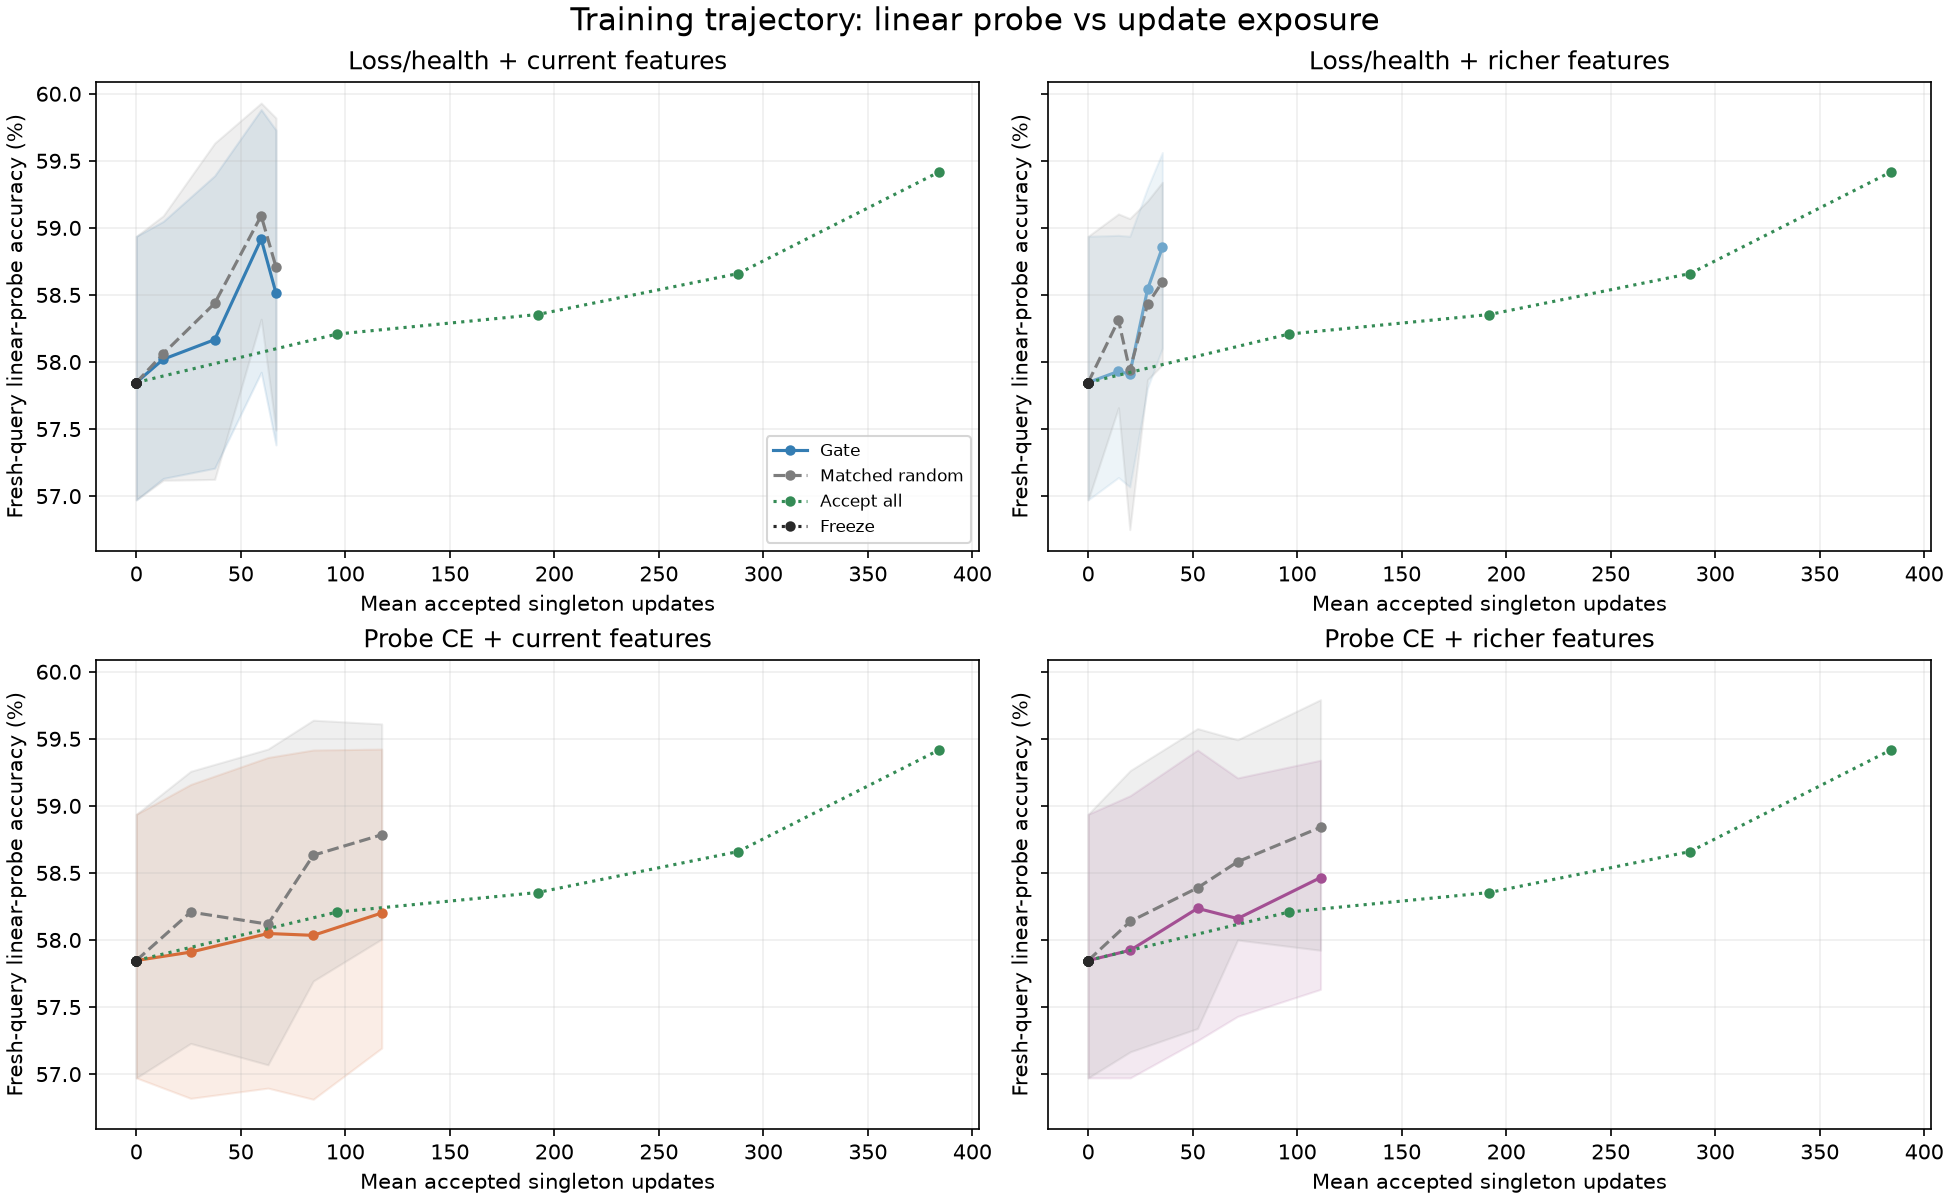

The same linear-probe checkpoints versus mean accepted singleton updates; freeze remains at zero updates.


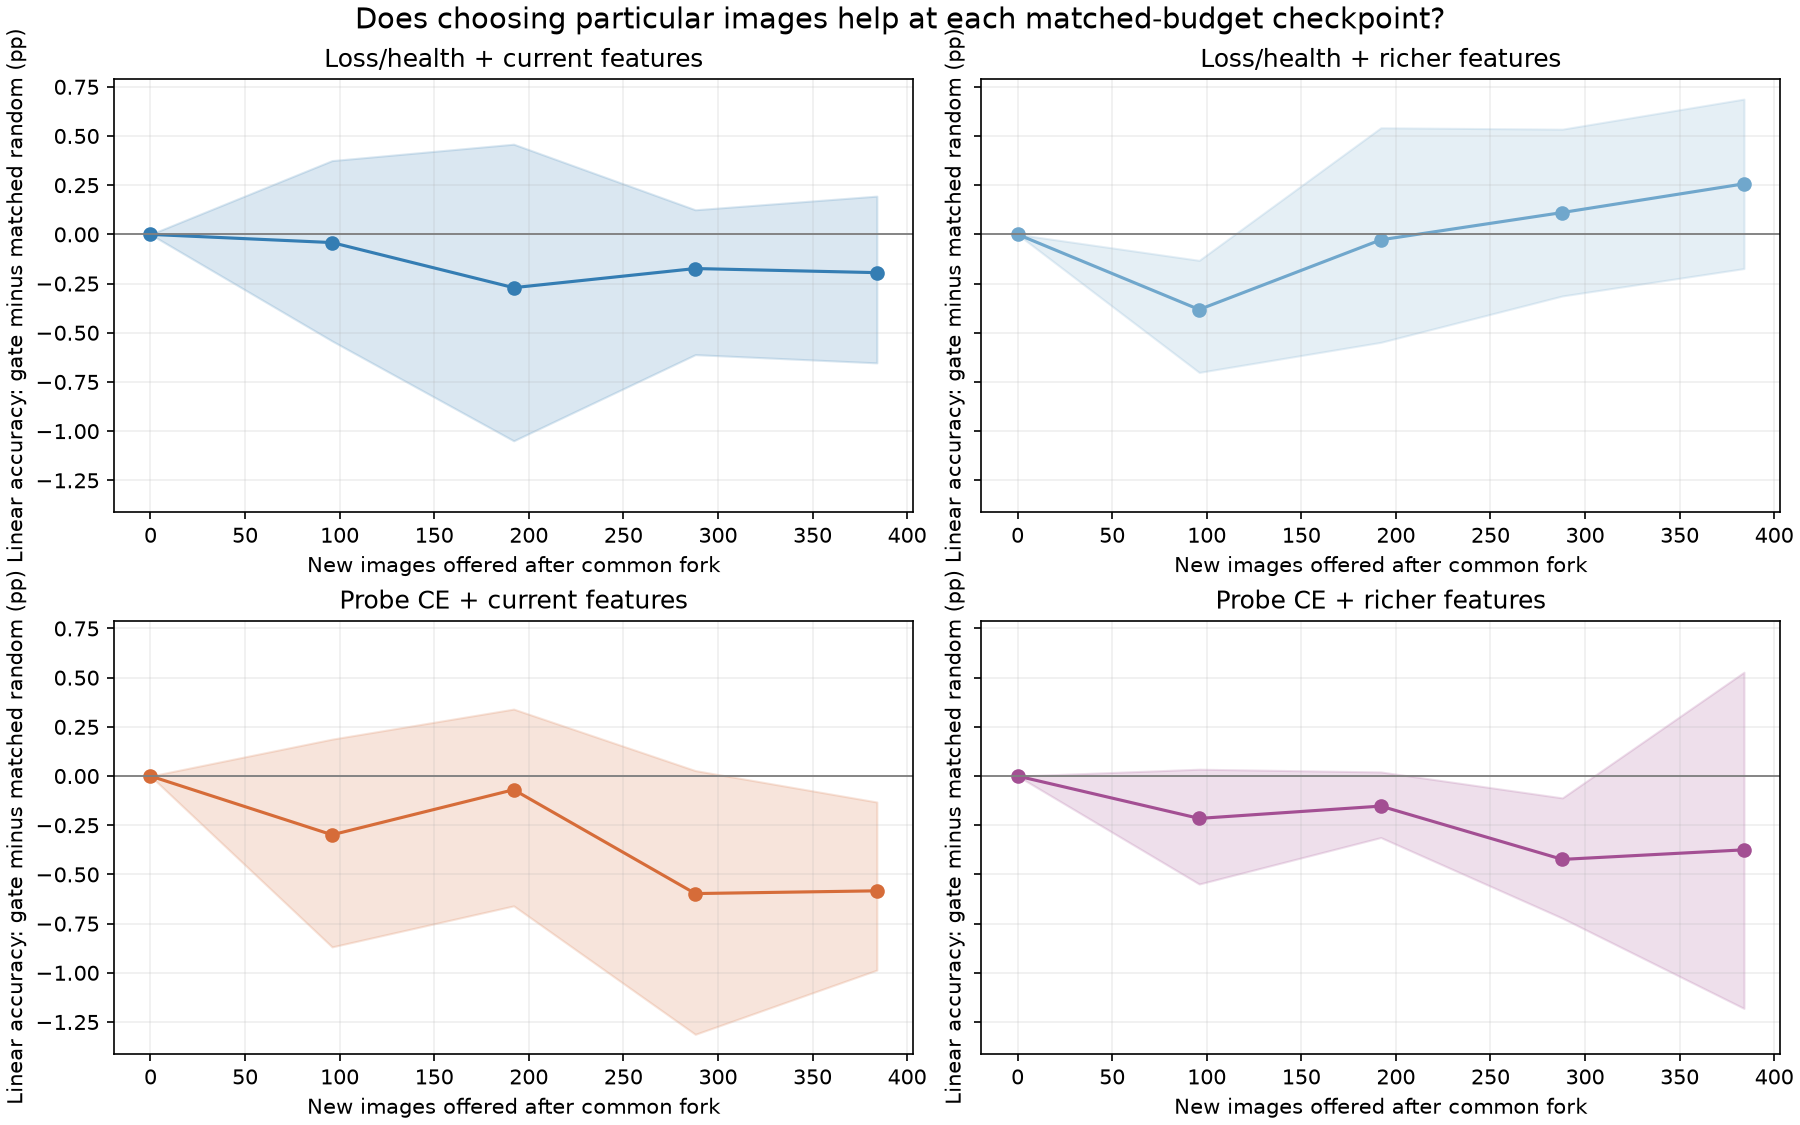

Paired accuracy gains over each gate's random control at every measured checkpoint. Update counts match at these clip ends; image identities and timing differ.


In [3]:
main=['J_base','J_rich','probe_base','probe_rich']
table(['Gate','Admission %','Fork accuracy %','Final accuracy %','Change pp','Gate minus random pp [95%]','Gate minus all pp [95%]'], [[k,f(100*s['arms'][k]['admission']),f(s['arms'][k]['metrics']['linear_accuracy_balanced']['before']),f(s['arms'][k]['metrics']['linear_accuracy_balanced']['after']),f(s['arms'][k]['metrics']['linear_accuracy_balanced']['change']),ci(s['comparisons'][k+'__random_'+k]['linear_accuracy_balanced']),ci(s['comparisons'][k+'__full']['linear_accuracy_balanced'])] for k in main])
table(['Contrast','Raw accuracy pp [95%]','Difference in gain above random pp [95%]'], [[k,ci(r['raw']['linear_accuracy_balanced']),ci(r['above_matched_random']['linear_accuracy_balanced'])] for k,r in s['factorial'].items()])


Gate,Admission %,Fork accuracy %,Final accuracy %,Change pp,Gate minus random pp [95%],Gate minus all pp [95%]
J_base,17.4045,57.8472,58.5139,0.666667,"-0.194444 [-0.652951, 0.194444]","-0.902778 [-1.99306, 0.256944]"
J_rich,9.24479,57.8472,58.8542,1.00694,"0.256944 [-0.173611, 0.6875]","-0.5625 [-1.36111, 0.0416667]"
probe_base,30.5773,57.8472,58.2014,0.354167,"-0.583333 [-0.986111, -0.131944]","-1.21528 [-1.96528, -0.340278]"
probe_rich,28.9497,57.8472,58.4653,0.618056,"-0.375 [-1.18073, 0.527778]","-0.951389 [-1.61111, -0.284549]"


Contrast,Raw accuracy pp [95%],Difference in gain above random pp [95%]
features_at_J,"0.340278 [-0.75, 1.27083]","0.451389 [-0.347222, 1.32639]"
features_at_probe,"0.263889 [-0.340278, 0.923611]","0.208333 [-0.673611, 1.22917]"
objective_at_base,"-0.3125 [-1.27083, 0.5]","-0.388889 [-0.826389, 0.0416667]"
objective_at_rich,"-0.388889 [-1.4375, 0.59809]","-0.631944 [-1.50694, 0.347222]"
objective_feature_interaction,"-0.0763889 [-1.23611, 1.5]","-0.243056 [-1.32639, 1]"


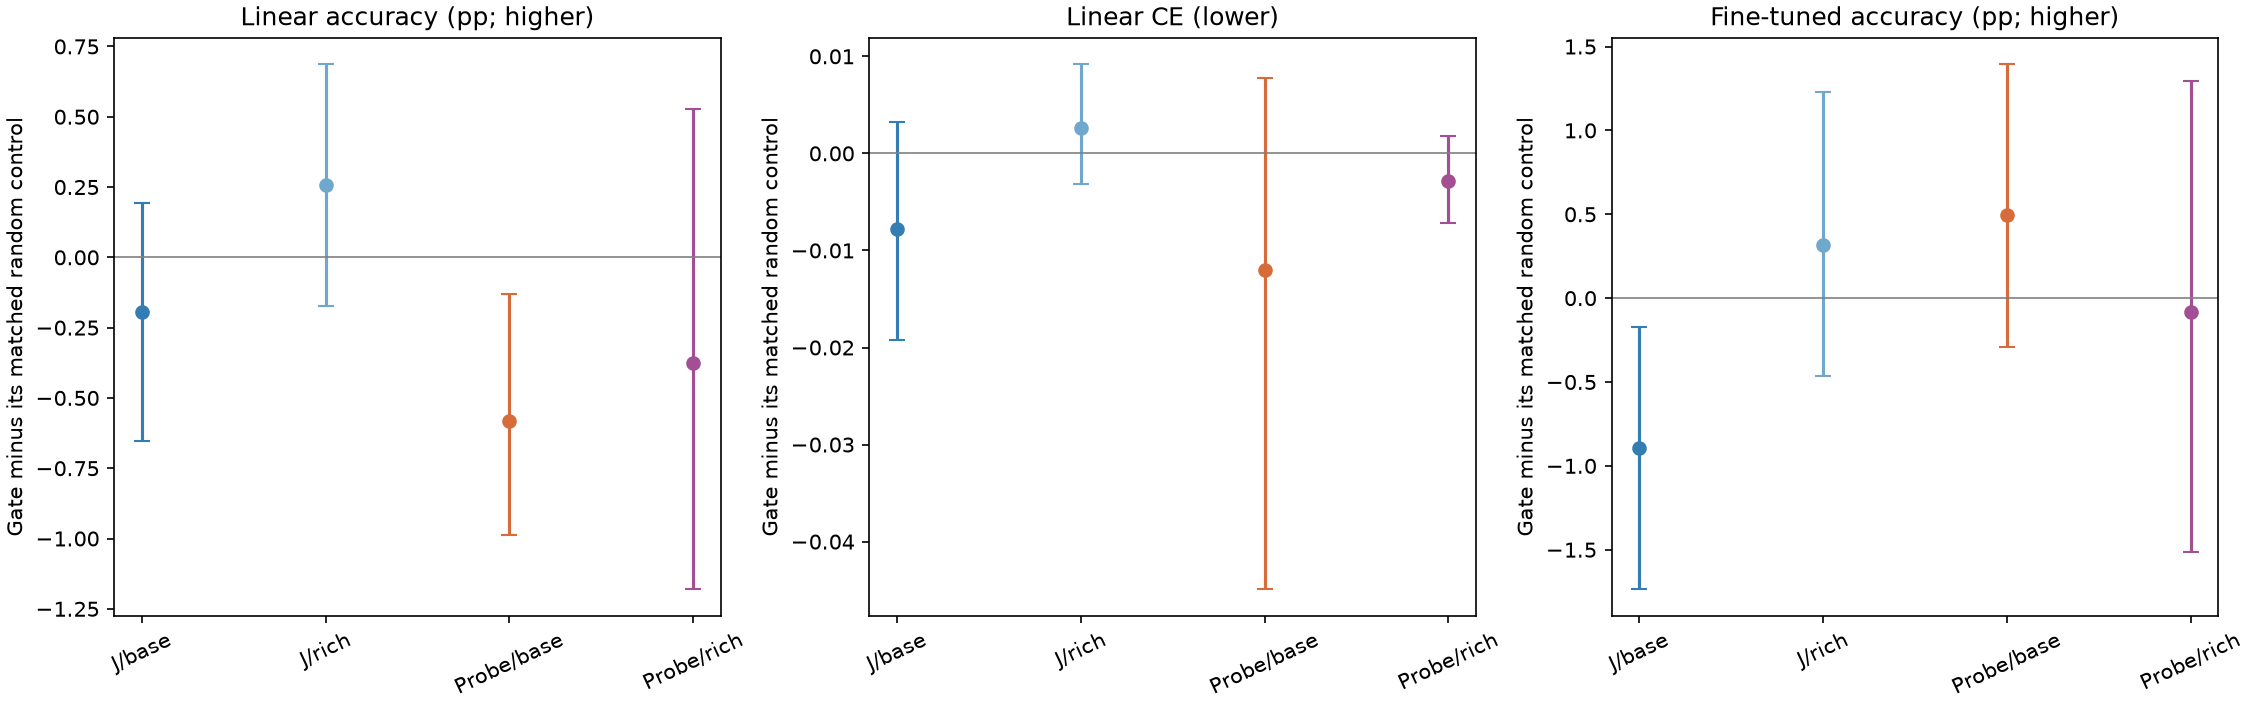

Each gate minus its own matched random control. All intervals retain whole histories, both seeds and all panels.


## Secondary trajectories and full endpoint measurements

CE is a probability loss; lower is preferred. Accuracy measures the winning class; higher is preferred. Improving one need not improve the other. The development-bank objective is distinct from fresh-query evaluation. Fine-tuning is measured only at the common fork and final endpoint, under100 copied supervised steps with batch32; there is no measured intermediate fine-tuning curve. SSL training remains batch1.


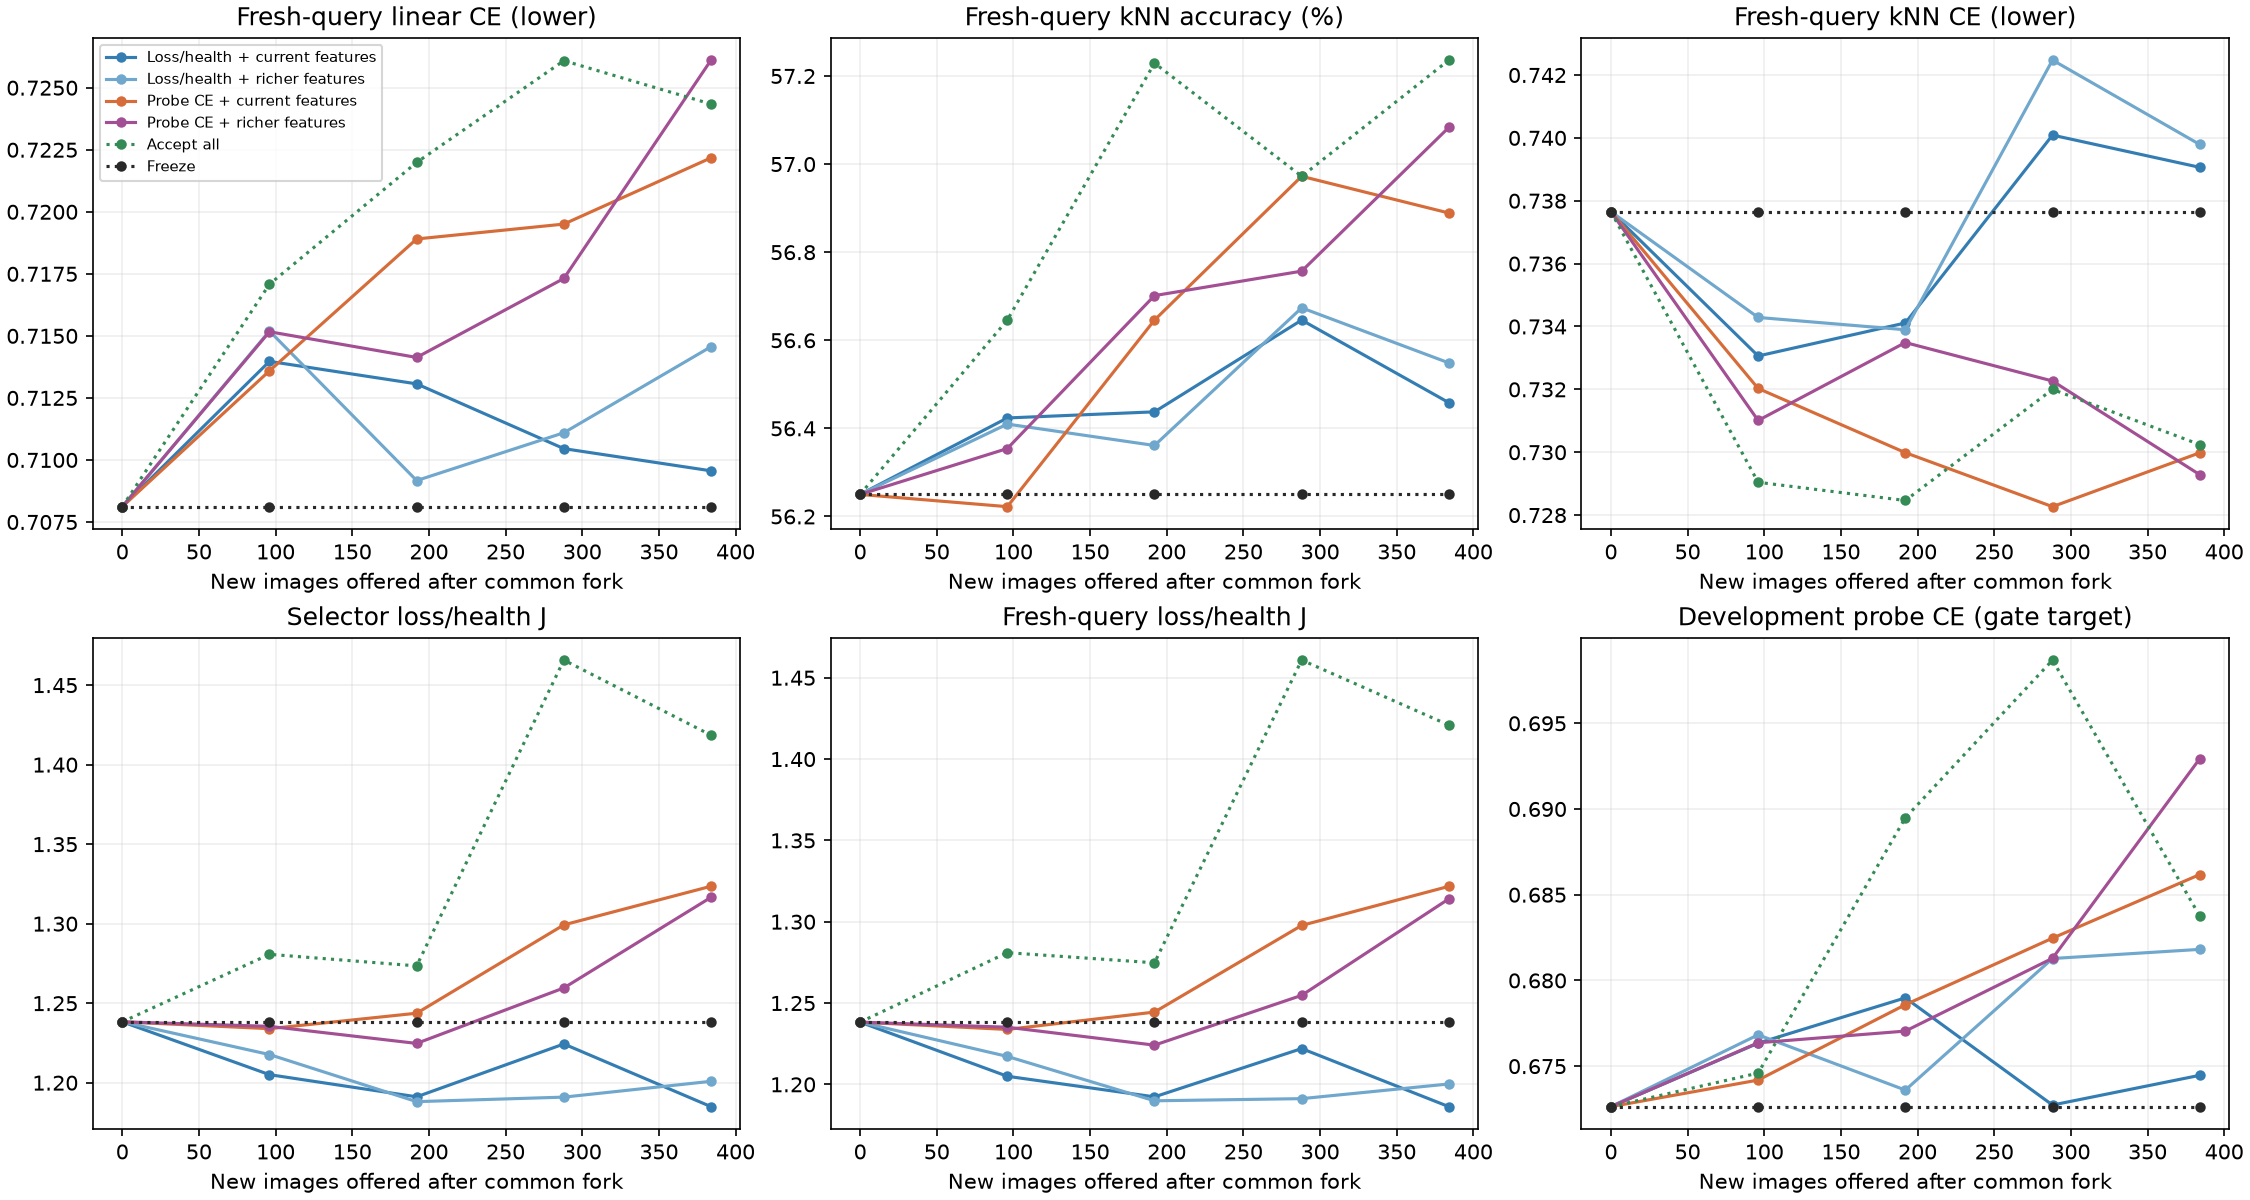

Measured linear/kNN losses, kNN accuracy and bank objectives over the stream.


In [4]:
downstream=[m for m in metrics if '_accuracy_' in m or '_ce_' in m]
table(['Endpoint change (accuracy pp; CE loss)',*main,'Accept all','Freeze'], [[m,*[f(s['arms'][k]['metrics'][m]['change']) for k in main+['full','hold']]] for m in downstream])
health=[m for m in metrics if m.startswith(('selector_','evaluation_'))]
table(['Health/objective change',*main,'Accept all','Freeze'], [[m,*[f(s['arms'][k]['metrics'][m]['change']) for k in main+['full','hold']]] for m in health])
table(['Metric','J/base minus random [95%]','J/rich minus random [95%]','Probe/base minus random [95%]','Probe/rich minus random [95%]'], [[m,*[ci(s['comparisons'][k+'__random_'+k][m]) for k in main]] for m in metrics])


Endpoint change (accuracy pp; CE loss),J_base,J_rich,probe_base,probe_rich,Accept all,Freeze
linear_accuracy_balanced,0.666667,1.00694,0.354167,0.618056,1.56944,0
linear_ce_balanced,0.00144427,0.00644618,0.0140572,0.017996,0.0162239,0
linear_accuracy_day,0.416667,0.555556,0.194444,0.291667,0.513889,0
linear_ce_day,0.0107217,0.00843405,0.0269168,0.0317502,0.013616,0
linear_accuracy_night,0.916667,1.45833,0.513889,0.944444,2.625,0
linear_ce_night,-0.00783317,0.00445831,0.00119763,0.00424183,0.0188317,0
knn_accuracy_balanced,0.208333,0.298611,0.638889,0.833333,0.986111,0
knn_ce_balanced,0.00141133,0.00213861,-0.00767014,-0.00836525,-0.00740759,0
knn_accuracy_day,0.541667,0.333333,0.694444,0.666667,0.625,0
knn_ce_day,0.0030942,0.0057497,0.00313262,-0.0062281,-0.00950726,0


Health/objective change,J_base,J_rich,probe_base,probe_rich,Accept all,Freeze
selector_objective,-0.0533499,-0.037404,0.0852595,0.0782991,0.180269,0
evaluation_objective,-0.0519781,-0.0380182,0.0834858,0.075807,0.182635,0
selector_rank,-0.16384,-0.0714978,-0.207227,-0.277407,-0.452073,0
selector_variance,-0.000385056,-0.000810249,-0.000910569,-0.000639025,-0.00125171,0
selector_covariance,-0.00033087,-0.000896196,-0.000829279,-0.000426865,-0.000965103,0
selector_cka,-0.0441396,-0.0150193,-0.0230809,0.0328218,0.0538641,0
selector_cosine,-0.129659,-0.0983059,-0.0215696,0.0453824,0.0811347,0
selector_feature_norm,0.00609899,0.0234846,-0.0699276,-0.0801921,-0.0788251,0
selector_bank_reconstruction,-0.058437,-0.0394967,0.0462125,0.0331623,0.102526,0
evaluation_rank,-0.167436,-0.0905978,-0.226507,-0.266179,-0.444211,0


Metric,J/base minus random [95%],J/rich minus random [95%],Probe/base minus random [95%],Probe/rich minus random [95%]
selector_objective,"-0.0331634 [-0.0584659, -0.00939046]","0.0018795 [-0.0124486, 0.0168413]","-0.00659673 [-0.0613188, 0.0353688]","-0.0256635 [-0.058814, 0.0116525]"
evaluation_objective,"-0.0325052 [-0.0579649, -0.0107537]","0.000435771 [-0.0133478, 0.0137716]","-0.00719963 [-0.0566898, 0.0318808]","-0.0229961 [-0.0515063, 0.00987866]"
development_probe_ce,"-0.012197 [-0.0322519, 0.00117254]","0.00394482 [-0.00268003, 0.0122049]","-0.0216082 [-0.0713659, 0.0120658]","-0.00426851 [-0.0147204, 0.00424605]"
selector_rank,"0.00821934 [-0.0867704, 0.132618]","-0.0515618 [-0.180457, 0.0727665]","0.0563619 [-0.0457419, 0.16855]","0.07151 [-0.0382916, 0.219337]"
selector_variance,"0.000178166 [-0.000190795, 0.000598332]","-0.000546726 [-0.00138629, 8.96317e-05]","0.000379542 [-0.000723335, 0.0014911]","0.000669706 [-6.1322e-05, 0.00178728]"
selector_covariance,"0.000288653 [-0.000135845, 0.000800921]","-0.000536256 [-0.00139905, 0.000140528]","0.000220468 [-0.000683059, 0.001124]","0.000721513 [4.28905e-05, 0.00168351]"
selector_cka,"-0.037565 [-0.0665373, -0.00832199]","-0.00753117 [-0.0519385, 0.0273775]","0.00744371 [-0.0260141, 0.0481497]","-0.019528 [-0.0928009, 0.0260733]"
selector_cosine,"-0.0334057 [-0.0585432, -0.0126757]","-0.00203588 [-0.0410073, 0.0288486]","0.0285403 [-0.0540222, 0.11897]","-0.0036859 [-0.0885416, 0.0694303]"
selector_feature_norm,"0.0306123 [-0.0252161, 0.0817145]","0.0282897 [-0.0248942, 0.0954806]","-0.0178624 [-0.0582143, 0.00460258]","0.0514674 [-0.0346455, 0.173303]"
selector_bank_reconstruction,"-0.0243528 [-0.0453533, -0.00871771]","-0.00234835 [-0.0132861, 0.00646401]","0.00786525 [-0.0175965, 0.026252]","-0.0111062 [-0.0237553, 0.00445212]"


## Does the next-image prediction work, and does its effect persist?

Each main gate has48 disposable same-parent candidate diagnostics, including rejected images. One position per clip is sampled uniformly from positions0..64 so a32-step continuation fits within the clip. This is a restricted phase population, not a dense-stream sample. H1 compares one realized image update with skipping the entire step. Validation instead targets a three-view mean, so its error magnitude is not directly comparable. H32 then applies the same31 future singleton updates to both branches. The predictor was fitted for H1, not H32. Forecast errors below target DEVELOPMENT-bank CE/J. Fresh-query effects measure transfer and are reported separately. No diagnostic changes a live decision or learner.


In [5]:
rows=[]
for arm in main:
    for target in ['J','probe']:
        r=s['forecast'][arm][target+'_all']
        rows.append([arm,target,r['n'],f(r['rmse']),f(r['mae']),f(r['zero_rmse']),f(r['zero_mae']),'undefined' if r['balanced_sign_accuracy'] is None else f(100*r['balanced_sign_accuracy'])])
table(['Gate','Target','N','RMSE','MAE','Zero RMSE','Zero MAE','Balanced direction %'],rows)
table(['Gate','H1 fresh-query accuracy effect pp [95%]','H32 effect pp [95%]','H1 fresh-query CE effect [95%]','H32 CE effect [95%]'], [[k,ci(s['persistence'][k]['H1_evaluation_probe_accuracy']),ci(s['persistence'][k]['H32_evaluation_probe_accuracy']),ci(s['persistence'][k]['H1_evaluation_probe_ce']),ci(s['persistence'][k]['H32_evaluation_probe_ce'])] for k in main])


Gate,Target,N,RMSE,MAE,Zero RMSE,Zero MAE,Balanced direction %
J_base,J,48,0.00573917,0.00389493,0.00600674,0.00382636,56.4428
J_base,probe,48,0.00462287,0.00317965,0.0025299,0.00172166,67.7778
J_rich,J,48,0.0139816,0.00880872,0.0136287,0.0079464,46.6087
J_rich,probe,48,0.00677758,0.00429969,0.0077774,0.00402919,46.1111
probe_base,J,48,0.00788465,0.00345176,0.00871496,0.00445089,68.8889
probe_base,probe,48,0.00559612,0.00333135,0.00320042,0.00160622,60.3175
probe_rich,J,48,0.00436789,0.00310561,0.00599402,0.00416714,60.9375
probe_rich,probe,48,0.00575529,0.00294811,0.0015505,0.000925292,63.3394


Gate,H1 fresh-query accuracy effect pp [95%],H32 effect pp [95%],H1 fresh-query CE effect [95%],H32 CE effect [95%]
J_base,"-0.0225694 [-0.109375, 0.0381944]","0.0798611 [-0.00520833, 0.177083]","0.000558783 [-0.000143032, 0.00137378]","-0.000220196 [-0.000451525, 1.11326e-05]"
J_rich,"0.125 [0.015625, 0.248264]","-0.0243056 [-0.142361, 0.0868056]","-0.000130453 [-0.000752257, 0.000474176]","0.000305069 [-0.000814837, 0.00147488]"
probe_base,"0.0104167 [-0.0572917, 0.078125]","-0.00520833 [-0.236198, 0.189236]","0.000425019 [-0.000392687, 0.0011928]","0.000226896 [-0.000593816, 0.00104206]"
probe_rich,"0.0364583 [-0.0226128, 0.0833767]","-0.0277778 [-0.204861, 0.107639]","0.000448166 [-8.41266e-05, 0.00129994]","-3.4473e-05 [-0.000540409, 0.000744426]"


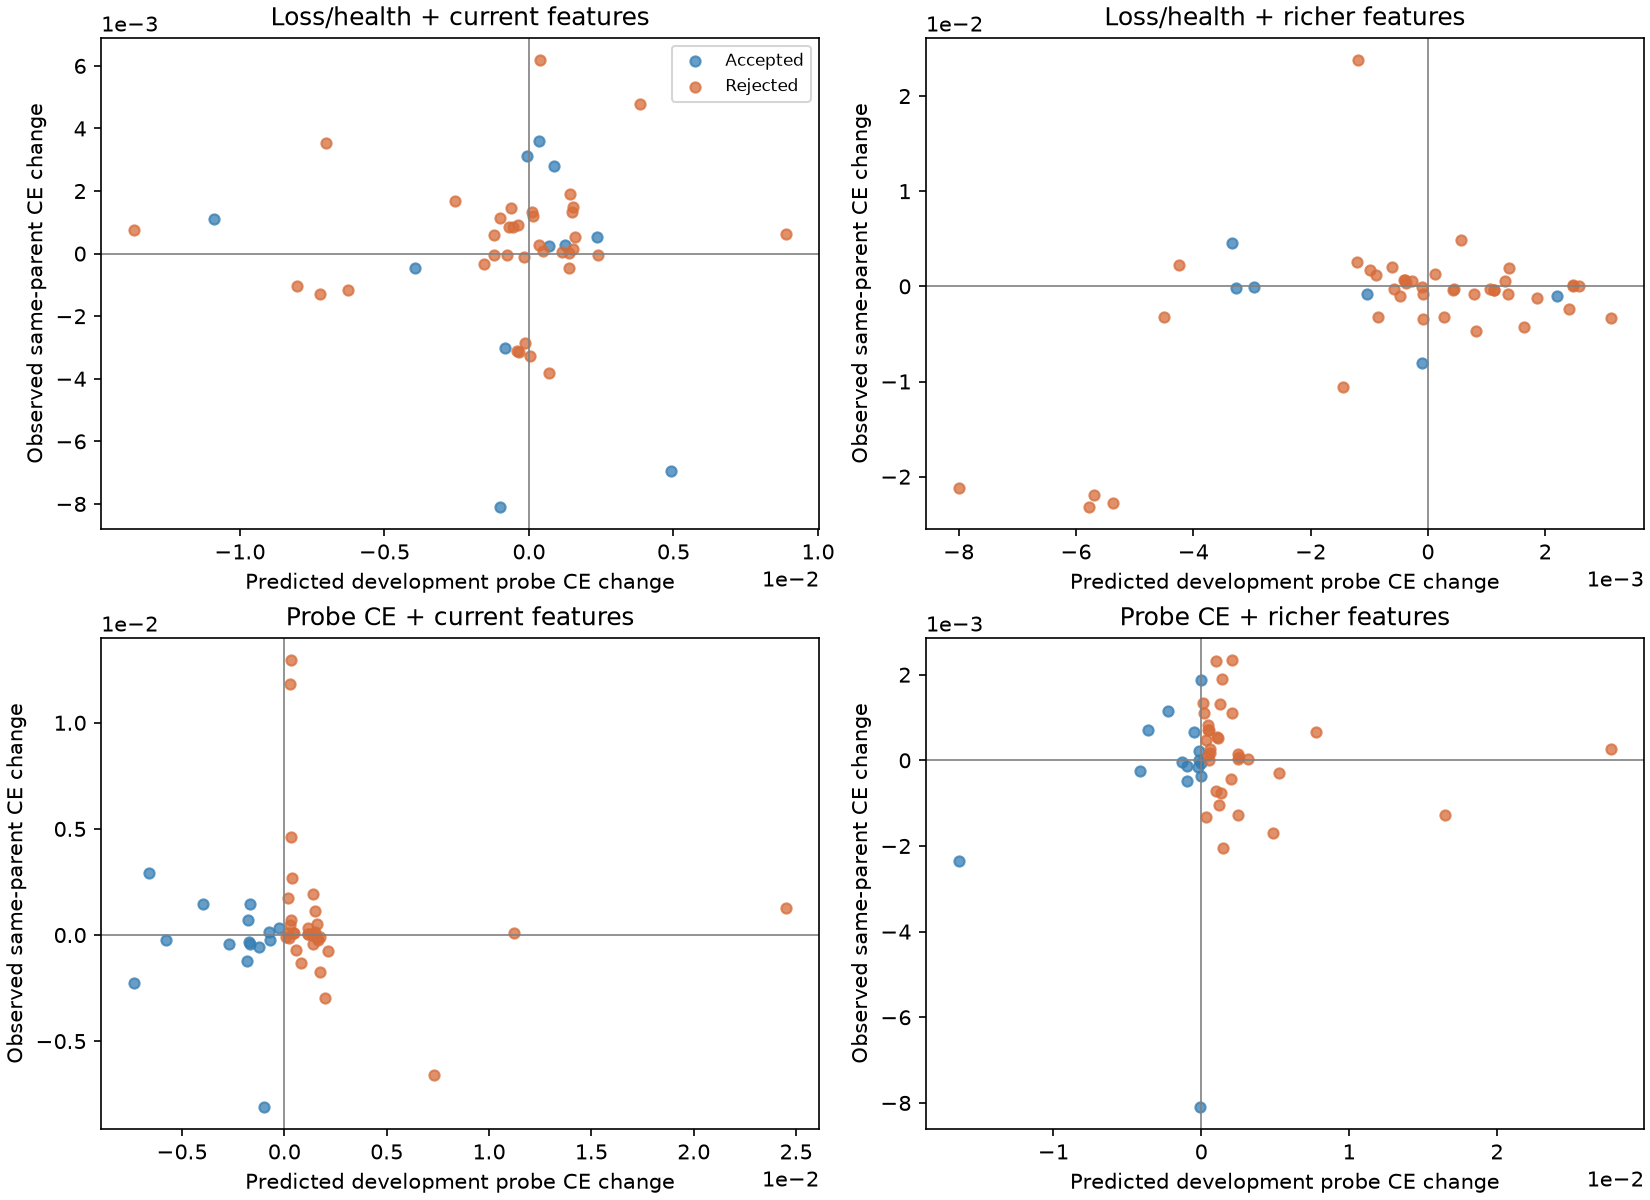

Frozen probe-target predictions versus measured immediate development CE effects, including rejected candidates.


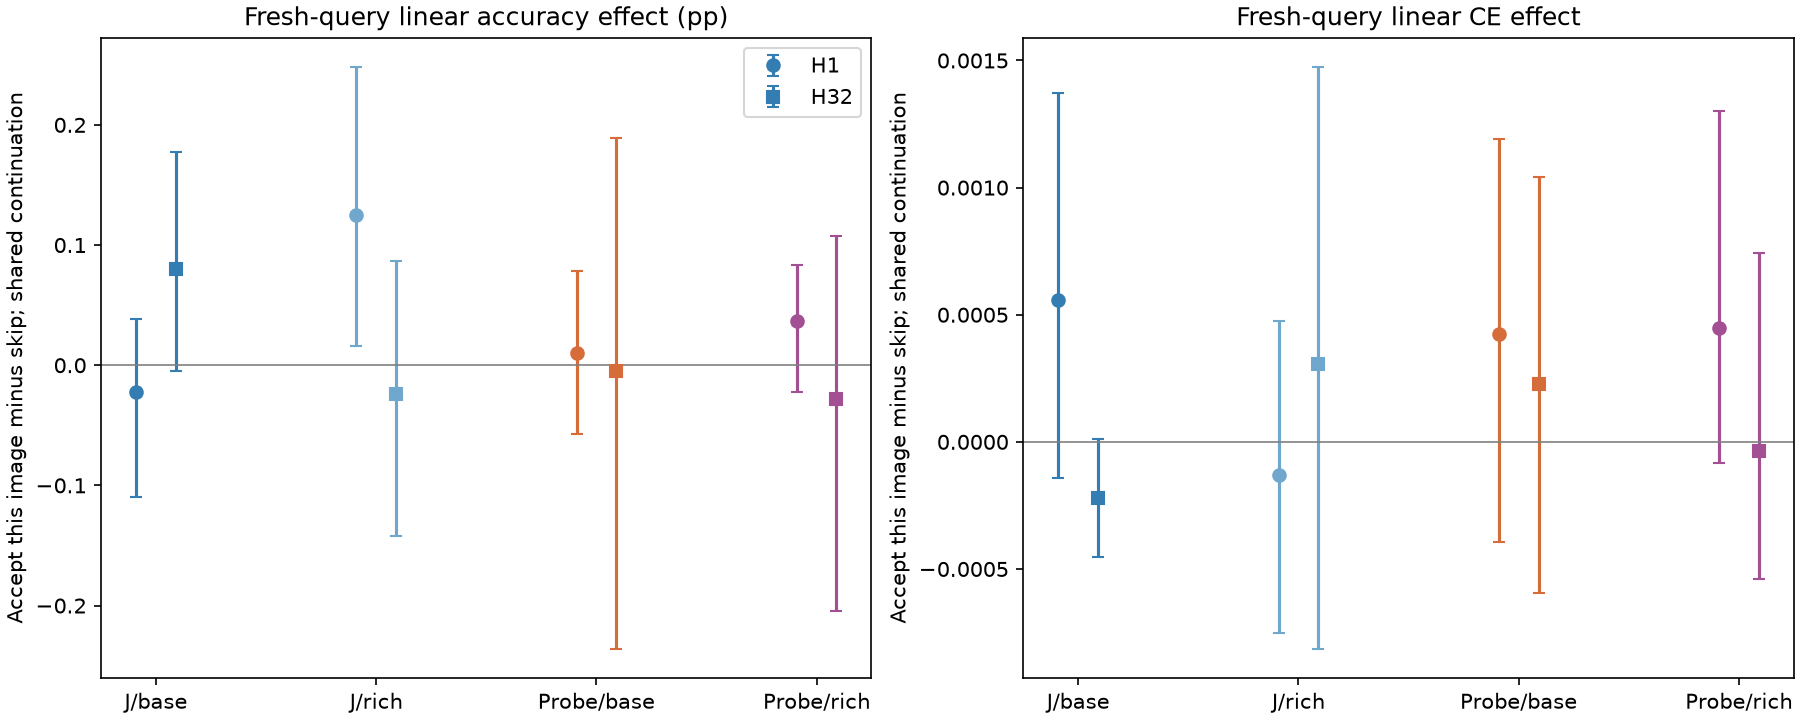

Measured H1 and H32 fresh-query effects of accepting one image versus skipping, under identical subsequent training.


## Cost, seed and panel sensitivity

Policy time includes feature extraction, required bank observations, prediction and accepted SSL training. Calibration, intake, checkpoint readers, diagnostic branches and verification are separate research costs. The current experiment prioritizes utility over processing speed. No speedup follows automatically from fewer optimizer steps.


In [6]:
table(['Policy','Accepted /4608','Admission %','Mean seconds /384 arrivals'], [[k,s['arms'][k]['accepted'],f(100*s['arms'][k]['admission']),f(s['arms'][k]['mean_policy_seconds'])] for k in arms])
table(['Gate','Health/history outside fitted coordinate ranges %','Any input outside range %'], [[k,f(100*s['arms'][k]['health_history_range_violation_fraction']),f(100*s['arms'][k]['any_feature_range_violation_fraction'])] for k in main+['J_state','probe_state']])
rows=[]
k=metrics.index('linear_accuracy_balanced')
for seed in np.unique(a['seeds']):
    take=a['seeds']==seed
    for arm in main:
        j=arms.index(arm); r=arms.index('random_'+arm)
        rows.append(['SSL seed '+str(seed),arm,f((a['after'][take,j,k]-a['before'][take,k]).mean()),f((a['after'][take,j,k]-a['after'][take,r,k]).mean())])
pk=a['reader_metrics'].tolist().index('linear_accuracy_balanced')
for panel in range(3):
    for arm in main:
        j=arms.index(arm); r=arms.index('random_'+arm)
        rows.append(['Support panel '+str(panel+1),arm,f((a['panels_after'][:,j,panel,pk]-a['panels_before'][:,panel,pk]).mean()),f((a['panels_after'][:,j,panel,pk]-a['panels_after'][:,r,panel,pk]).mean())])
table(['Subset','Gate','Accuracy change pp','Gate minus random pp'],rows)


Policy,Accepted /4608,Admission %,Mean seconds /384 arrivals
J_base,802,17.4045,11.5069
J_rich,426,9.24479,31.8461
probe_base,1409,30.5773,15.5052
probe_rich,1334,28.9497,42.8443
J_state,281,6.09809,7.59904
probe_state,1213,26.3238,13.794
random_J_base,802,17.4045,1.25258
random_J_rich,426,9.24479,0.669277
random_probe_base,1409,30.5773,2.2442
random_probe_rich,1334,28.9497,2.08796


Gate,Health/history outside fitted coordinate ranges %,Any input outside range %
J_base,20.5729,80.0564
J_rich,16.3411,89.0625
probe_base,12.3915,75.2387
probe_rich,13.3898,87.4132
J_state,9.65712,51.671
probe_state,12.1094,49.8915


Subset,Gate,Accuracy change pp,Gate minus random pp
SSL seed 5003,J_base,0.944444,0.0138889
SSL seed 5003,J_rich,1.45833,0.722222
SSL seed 5003,probe_base,0.0138889,-1.04167
SSL seed 5003,probe_rich,0.444444,-1.16667
SSL seed 5009,J_base,0.388889,-0.402778
SSL seed 5009,J_rich,0.555556,-0.208333
SSL seed 5009,probe_base,0.694444,-0.125
SSL seed 5009,probe_rich,0.791667,0.416667
Support panel 1,J_base,-0.291667,-0.291667
Support panel 1,J_rich,0.25,0.125


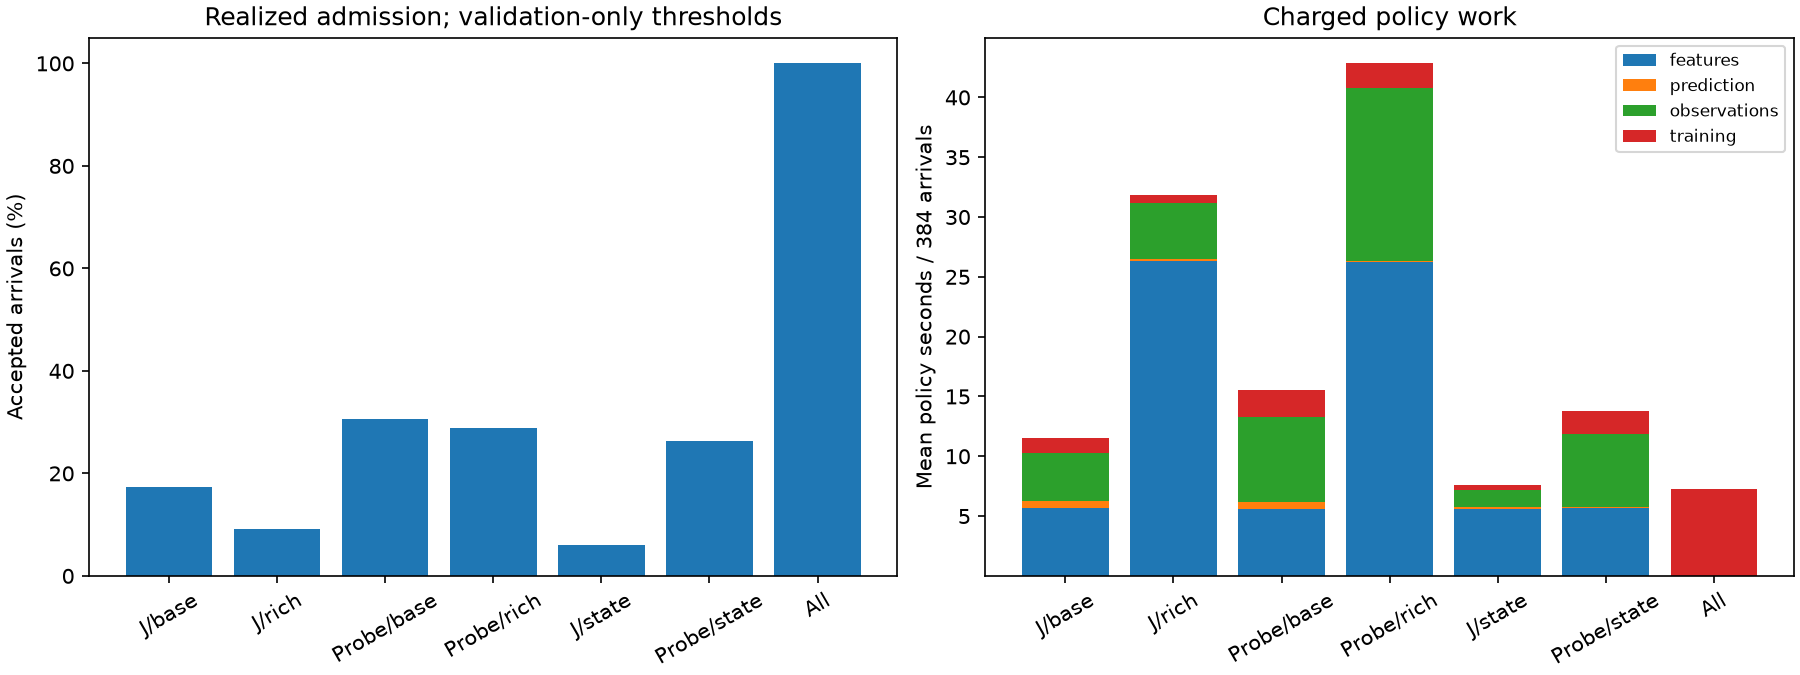

Realized admission and charged policy work; no live admission fallback is forced.


## Limits and reproducibility

One warm initialization, six fresh clip-ID histories, two training seeds and reused support panels limit generalization. Clip IDs do not establish recording-session independence. J and CE use different development reference banks, so objective contrasts include bank composition. Curves, panels, seeds and metrics are dependent; all intervals are exploratory and unadjusted across outcomes. Raw objective/feature contrasts mix content and exposure when admission rates differ. The above-random contrasts help interpret that difference but do not make update timing or model state identical. All four main gates are reported; final results choose no new parameter, objective or threshold. The task-informed rich selector is not fully label-free. Coordinate-range checks do not test the full joint input distribution. Development origins occur at clip phases0,32,64; the live stream includes all96 phases, while continuation diagnostics cover phases0..64.

Inputs, frozen models, complete logs, checkpoint probabilities, same-parent branches, verification records and source snapshots are preserved in the output directory. The report and notebook are generated from `summary.json`, `endpoints.npz` and the audit records. The verification records state which updates and observations were physically replayed; saved-input decision reconstruction alone is not a replay of every live inference.


## What this says about the three improvement angles

**Objective.** Switching to development probe CE did not improve final linear-probe accuracy. CE is a smoother target, but it is not interchangeable with accuracy. Accept-all increased accuracy while its evaluation CE rose by 0.01622 and its evaluation loss/health J rose by 0.18263. The objective comparison also changes reference-bank composition, so it is a comparison of complete recipes.

J/current also uses this study's calibration split and threshold rule; it preserves study66's objective/input design but does not replay its original fitted gate.

**Features.** The richer bank/gradient inputs do not establish an accuracy advantage. At J, their difference in accuracy gain above the respective random controls is 0.451389 [-0.347222, 1.32639] pp; at probe CE it is 0.208333 [-0.673611, 1.22917] pp. Both intervals include zero. The probe-CE magnitude forecasts on their own live sampled paths also miss the zero-change baseline:

- **probe_base:** live development-CE RMSE/MAE 0.00560/0.00333, versus zero-change 0.00320/0.00161.
- **probe_rich:** live development-CE RMSE/MAE 0.00576/0.00295, versus zero-change 0.00155/0.00093.

These audits cover one candidate in phases0..64 per clip, including rejected images. They do not estimate dense-stream prediction accuracy. Different policies visit different states, so their raw errors are not a controlled comparison of feature designs.

**Computation.** The richer J and probe policies cost 4.36x and 5.87x accept-all processing, respectively. Most of the extra work is feature extraction and required bank observation. No established primary-utility advantage currently justifies that overhead.

**Path forward.** Keep singleton updates, but do not promote these revised gates. A useful next test would collect accept/skip labels from deliberately mixed-admission development paths, then check which continuous target actually tracks refitted linear-probe accuracy. Here, calibration uses full-update states and live filtering changes their distribution. That is a structural concern and a testable explanation, rather than a demonstrated cause of the negative result. This notebook does not run that follow-up.
